# 02 · Baselines

This notebook trains and evaluates every **single-modality** model. Each one uses either the PV history or the sky images, never both. The fusion model comes later and must beat the best of these.

| Section | Model | Input | Output |
|---|---|---|---|
| 3 | Persistence | PV now | PV at t+h = PV now |
| 4 | Smart persistence | clear-sky index now | k now × clear-sky power at t+h |
| 5 | PV history (MLP / LSTM / Transformer) | last 15 min of PV + sun position | probabilistic forecast |
| 6 | Clear-sky index history (MLP / LSTM / Transformer) | last 15 min of k + sun position | probabilistic forecast |
| 7 | Sky images (CNN) | sky images at t−10, t−5, t + sun position | probabilistic forecast |
| 8 | **Results** of all models | | |

Sections 0–2 prepare the data and the shared tools (metrics, training loop, cross-validation). Sections 3–7 can then be run one after another; each saves its out-of-fold predictions, and a model that has already been trained is skipped. Section 8 compares all models. The test set is **not used** in this notebook.

## 0 · Setup

Paths, constants and training settings used by every model.

In [1]:
import json, math, time
from dataclasses import dataclass
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats, special

# paths
DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
H5_PATH = DATA_DIR / "2017_2019_images_pv_processed.hdf5"
RESULTS_DIR = PROCESSED_DIR / "baselines"
PRED_DIR = RESULTS_DIR / "predictions"         # out-of-fold predictions, one file per model and horizon
LOG_DIR = RESULTS_DIR / "train_logs"           # training log, one file per model and horizon
IMAGE_CACHE = PROCESSED_DIR / "images_rgb.npy" # all sky images as one array (built in section 7)
for p in [PRED_DIR, LOG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# problem setup
HORIZONS = [15, 30, 60]          # forecast horizons (minutes)
HISTORY_MIN = 15                 # PV / k history: t-14 ... t
IMAGE_OFFSETS = [10, 5, 0]       # sky images at t-10, t-5, t
N_FOLDS = 5
SEED = 1
WEATHER_BINS = ["clear", "variable", "overcast"]

# training settings (the same for every learned model)
TRAIN_CONFIG = dict(
    lr=1e-3, 
    weight_decay=1e-4, 
    batch_size=256,
    max_epochs=60, 
    early_stop_patience=10,     # stop when the early-stopping NLL has not improved for 10 epochs
    lr_patience=3, 
    lr_min=1e-5,                # halve the learning rate after 3 epochs without improvement
    grad_clip=1.0,
)
RETRAIN = False                  # False: skip models whose predictions already exist

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

device: cuda NVIDIA GeForce RTX 4070 SUPER


## 1 · Data

### 1.1 Samples for each horizon

The preprocessing notebook saved one row per minute (`meta_processed.csv`) and, for each horizon, the list of valid samples (`samples_h{h}.csv`), where each sample points to its start row t and its target row t+h. Here we collect, for every sample:

| Field | Meaning |
|---|---|
| `pv_history`, `k_history` | PV (kW) and clear-sky index k at t−14 … t |
| `sun` | sun position at t and at t+h: sin(elevation), sin(azimuth), cos(azimuth); known in advance |
| `image_rows` | rows of the sky images at t−10, t−5, t |
| `pv_now`, `k_now` | PV and k at t (used by persistence) |
| `pv_target` | PV at t+h in kW: **what every model is evaluated on** |
| `k_target`, `clear_sky_target` | k and clear-sky power at t+h (models that predict k are converted back to kW with `clear_sky_target`) |

Only trainval samples (folds 0–4) are loaded.

In [2]:
minutes = pd.read_csv(PROCESSED_DIR / "meta_processed.csv",
                      usecols=["split", "img_idx", "date", "pv_kw", "k", "p_clear", "sun_elev", "sun_azim"])
elev, azim = np.deg2rad(minutes["sun_elev"].to_numpy()), np.deg2rad(minutes["sun_azim"].to_numpy())
sun_per_minute = np.stack([np.sin(elev), np.sin(azim), np.cos(azim)], axis=1).astype(np.float32)

@dataclass
class HorizonData:
    horizon: int
    samples: pd.DataFrame          # row_t, row_y, fold, weather (kept for saving predictions)
    fold: np.ndarray
    weather: np.ndarray
    day: np.ndarray
    pv_history: np.ndarray         # (n, 15)
    k_history: np.ndarray          # (n, 15)
    sun: np.ndarray                # (n, 6)
    image_rows: np.ndarray         # (n, 3)
    pv_now: np.ndarray
    k_now: np.ndarray
    pv_target: np.ndarray
    k_target: np.ndarray
    clear_sky_target: np.ndarray

def load_horizon(h):
    s = pd.read_csv(PROCESSED_DIR / f"samples_h{h}.csv")
    s = s[s["fold"] >= 0].reset_index(drop=True)                 # trainval only
    t, y = s["row_t"].to_numpy(), s["row_y"].to_numpy()
    history_rows = t[:, None] + np.arange(-HISTORY_MIN + 1, 1)   # t-14 ... t
    pv, k = minutes["pv_kw"].to_numpy(np.float32), minutes["k"].to_numpy(np.float32)
    return HorizonData(
        horizon=h, samples=s[["row_t", "row_y", "fold", "weather"]],
        fold=s["fold"].to_numpy(), weather=s["weather"].to_numpy(), day=minutes["date"].to_numpy()[t],
        pv_history=pv[history_rows], k_history=k[history_rows],
        sun=np.concatenate([sun_per_minute[t], sun_per_minute[y]], axis=1),
        image_rows=t[:, None] - np.array(IMAGE_OFFSETS),
        pv_now=pv[t], k_now=k[t],
        pv_target=pv[y], k_target=k[y], clear_sky_target=minutes["p_clear"].to_numpy(np.float32)[y])

DATA = {h: load_horizon(h) for h in HORIZONS}
print(pd.DataFrame({f"{h} min": pd.Series(DATA[h].fold).value_counts().sort_index() for h in HORIZONS})
      .rename_axis("fold"))

      15 min  30 min  60 min
fold                        
0      59072   57402   54320
1      59464   57854   54791
2      59771   58114   54948
3      62175   60562   57383
4      60242   58590   55548


### 1.2 Days held out for early stopping

In each cross-validation round, models are trained on 4 folds and evaluated on the 5th, which is never seen during training. Early stopping therefore uses its own data: **10% of the training days** of each round, chosen at random (whole days, fixed seed). The same days are used for every model and horizon and are saved to `early_stop_days.json`.

`split_masks` returns the three parts of one round: **fit** (used to train and to compute the standardisation), **early stop**, and **evaluate** (the held-out fold).

In [3]:
split_days = pd.read_csv(PROCESSED_DIR / "split_days.csv")
trainval_days = split_days[split_days["fold"] >= 0]

EARLY_STOP_DAYS = {}
for fold in range(N_FOLDS):
    train_days = np.sort(trainval_days.loc[trainval_days["fold"] != fold, "date"].to_numpy())
    rng = np.random.default_rng(SEED + fold)
    EARLY_STOP_DAYS[fold] = sorted(rng.choice(train_days, size=round(0.1 * len(train_days)), replace=False))
    print(f"round {fold}: {len(train_days)} training days, {len(EARLY_STOP_DAYS[fold])} for early stopping")

with open(RESULTS_DIR / "early_stop_days.json", "w") as fp:
    json.dump(EARLY_STOP_DAYS, fp, indent=1)

def split_masks(data, fold):
    in_train = data.fold != fold
    early_stop = in_train & np.isin(data.day, EARLY_STOP_DAYS[fold])
    return in_train & ~early_stop, early_stop, data.fold == fold       # fit, early stop, evaluate

round 0: 398 training days, 40 for early stopping
round 1: 399 training days, 40 for early stopping
round 2: 396 training days, 40 for early stopping
round 3: 396 training days, 40 for early stopping
round 4: 399 training days, 40 for early stopping


## 2 · Shared functions

### 2.1 Forecast metrics

Every model outputs a **Student-t distribution** for PV at t+h: a centre μ, a scale σ and degrees of freedom ν.

Because the errors are heavy-tailed. Most of the time the next minutes look like the last ones and the error is tiny, but sometimes a cloud arrives that the history could not announce and the error is huge. In a first run with a Gaussian output, the worst 0.1% of samples made up 40% of the 60-minute NLL, and single days changed the result of a whole fold. A Student-t with a learned ν handles both cases.

All metrics are computed **in kW**, per fold and per weather bin:

- **Accuracy:** RMSE, MAE, and the skill score 1 − RMSE / RMSE(smart persistence).
- **Uncertainty:** coverage of the central 90% interval (target 0.90), its mean width, negative log-likelihood (NLL), CRPS (closed form for the Student-t), and the Winkler score (interval width plus 2/0.1 times the distance by which the true value falls outside). Lower is better for all of them except coverage.

These are the scores before conformal calibration, which is done later on the saved predictions.

In [4]:
# compute CRPS
def crps_student_t(z, nu):
    # CRPS of a standard Student-t at z (multiply by sigma for the scaled distribution)
    return (z * (2 * stats.t.cdf(z, nu) - 1) + 2 * stats.t.pdf(z, nu) * (nu + z ** 2) / (nu - 1) - 2 * np.sqrt(nu) * special.beta(0.5, nu - 0.5) / ((nu - 1) * special.beta(0.5, nu / 2) ** 2))

# compute metrics listed above: RMSE, MAE, coverage, width, NLL, CRPS, Winkler
def compute_metrics(y, mu, sigma, nu):
    error = y - mu
    z = error / sigma
    q = stats.t.ppf(0.95, nu)                       # 90% central interval: mu ± q * sigma
    low, high = mu - q * sigma, mu + q * sigma
    return {
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAE": np.mean(np.abs(error)),
        "coverage": np.mean((y >= low) & (y <= high)),
        "width": np.mean(high - low),
        "NLL": np.mean(np.log(sigma) - stats.t.logpdf(z, nu)),
        "CRPS": np.mean(sigma * crps_student_t(z, nu)),
        "Winkler": np.mean((high - low) + (2 / 0.1) * ((low - y) * (y < low) + (y - high) * (y > high))),
    }

# return metrics for all folds and all weathers
def evaluate_predictions(pred):
    # metrics for every fold and weather bin ("all" = every sample of the fold)
    rows = []
    for fold in range(N_FOLDS):
        for weather in ["all"] + WEATHER_BINS:
            p = pred[(pred["fold"] == fold) & ((pred["weather"] == weather) | (weather == "all"))]
            m = compute_metrics(*(p[c].to_numpy() for c in ["y", "mu", "sigma", "nu"]))
            rows.append({"fold": fold, "weather": weather, "n": len(p), **m})
    return pd.DataFrame(rows)

def prediction_file(model, h):
    return PRED_DIR / f"{model}_h{h}.csv"

# save the result as csv
def save_predictions(model, h, mu, sigma, nu):
    pred = DATA[h].samples.copy()
    pred["y"], pred["mu"], pred["sigma"], pred["nu"] = DATA[h].pv_target, mu, sigma, nu
    assert not pred[["mu", "sigma", "nu"]].isna().any().any()
    pred.to_csv(prediction_file(model, h), index=False)
    return pred

### 2.2 Output head and training loop

All learned models end with the same **output head**: a small layer, then **separate heads for μ and σ** (σ = softplus + a small floor) and one learned ν for the whole model. Separate heads are kept so that the fusion model can later route the image features to μ only, σ only, or both.

**Training** is identical for every learned model:

- loss: Student-t negative log-likelihood; the first epoch uses MSE on μ as a warm-up, because σ is meaningless before training;
- AdamW (learning rate 1e-3, weight decay 1e-4), batch size 256, gradient clipping at 1.0;
- after each epoch the NLL on the early-stopping days is computed; the learning rate is halved after 3 epochs without improvement (down to 1e-5), training stops after 10 epochs without improvement (at most 60 epochs), and the best epoch is kept.

In [5]:
# the last layer of all models
# no matter is time series or CNN, the last layer will output mean, sigma, nu for student-t distribution
class StudentTHead(nn.Module):
    def __init__(self, n_in, hidden=128, sigma_min=1e-3):
        # 128 -> 64 -> 1
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU())
        self.mu_head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))
        self.sigma_head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))
        self.nu_raw = nn.Parameter(torch.tensor(1.0))
        self.sigma_min = sigma_min

    def forward(self, features):
        x = self.shared(features)

        mu = self.mu_head(x).squeeze(-1)

        # sigma must be positive
        sigma = F.softplus(self.sigma_head(x)).squeeze(-1) + self.sigma_min

        # nu bust bigger than 2
        nu = 2 + F.softplus(self.nu_raw)

        return mu, sigma, nu

# define the loss function as NLL of the student-t distribution
def student_t_nll(mu, sigma, nu, y):
    z = (y - mu) / sigma
    return (torch.lgamma(nu / 2) - torch.lgamma((nu + 1) / 2) + 0.5 * torch.log(nu * math.pi) + torch.log(sigma) + (nu + 1) / 2 * torch.log1p(z ** 2 / nu)).mean()

In [6]:
# forward trainning function
def forward_pass(model, batch):
    # mixed precision for the CNN (faster); outputs back to float32 for the loss
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=getattr(model, "use_amp", False)):
        mu, sigma, nu = model(batch)
    return mu.float(), sigma.float(), nu.float()

# predict function
@torch.no_grad()
def predict(model, get_batch, idx, chunk=1024):
    model.eval()
    mus, sigmas = [], []
    for i in range(0, len(idx), chunk):
        mu, sigma, nu = forward_pass(model, get_batch(idx[i:i + chunk]))
        mus.append(mu)
        sigmas.append(sigma)
    return torch.cat(mus), torch.cat(sigmas), nu

# trainning function
def train_model(model, get_batch, target, fit_idx, stop_idx):
    # configure setting
    cfg = TRAIN_CONFIG
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=cfg["lr_patience"], min_lr=cfg["lr_min"])
    best_nll, best_epoch, best_state, bad_epochs = np.inf, 0, None, 0

    # run 60 epoches and early stopping is used
    for epoch in range(cfg["max_epochs"]):
        model.train()
        order = fit_idx[torch.randperm(len(fit_idx), device=DEVICE)]
        for i in range(0, len(order), cfg["batch_size"]):
            idx = order[i:i + cfg["batch_size"]]
            
            # forward trainning function
            mu, sigma, nu = forward_pass(model, get_batch(idx, train=True))   # train=True: augment images

            # only do MSE at the first round, because NLL is meaningless at the beginning because no sigma
            # then use self-defined loss function: NLL of the student-t distribution
            y = target[idx]
            loss = F.mse_loss(mu, y) if epoch == 0 else student_t_nll(mu, sigma, nu, y)

            # backward propogation
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()

        # early stopping and keep the best outpu
        mu, sigma, nu = predict(model, get_batch, stop_idx)
        stop_nll = student_t_nll(mu, sigma, nu, target[stop_idx]).item()
        if epoch == 0:
            continue
        sched.step(stop_nll)
        if stop_nll < best_nll:
            best_nll, best_epoch, bad_epochs = stop_nll, epoch, 0
            best_state = {n: v.detach().clone() for n, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["early_stop_patience"]:
                break

    model.load_state_dict(best_state)
    return dict(epochs=epoch + 1, best_epoch=best_epoch, early_stop_nll=round(best_nll, 4))

### 2.3 Cross-validation

`cross_validate` runs the 5 rounds for one model and one horizon. In each round it:

1. builds the inputs with the model's `prepare` function, which standardises them with the **fit** part of the round only;
2. trains a fresh model (fixed seed per round);
3. predicts the held-out fold and converts the prediction back to kW;
4. saves the out-of-fold predictions of all 5 rounds and the training log.

`run_models` calls it for a list of models and all horizons, and skips any model and horizon that already has predictions (unless `RETRAIN = True`).

In [7]:
# put everything to GPU
def gpu(a, dtype=torch.float32):
    return torch.as_tensor(np.ascontiguousarray(a), dtype=dtype, device=DEVICE)

# 5-fold cross validation
def cross_validate(name, h, build_model, prepare):
    data = DATA[h]
    n = len(data.fold)
    mu_kw, sigma_kw, nu_all = np.full(n, np.nan), np.full(n, np.nan), np.full(n, np.nan)
    
    log = []
    for fold in range(N_FOLDS):
        start = time.time()
        fit, early_stop, evaluate = split_masks(data, fold)
        get_batch, target, (y_mean, y_std), to_kw = prepare(data, fit)

        # set a fixed seed
        torch.manual_seed(SEED * 100 + fold)
        model = build_model().to(DEVICE)

        # train and predict
        info = train_model(model, get_batch, target, gpu(np.flatnonzero(fit), torch.long), gpu(np.flatnonzero(early_stop), torch.long))
        mu, sigma, nu = predict(model, get_batch, gpu(np.flatnonzero(evaluate), torch.long))

        # convert it back to KW for evaluation
        mu_kw[evaluate] = (mu.cpu().numpy() * y_std + y_mean) * to_kw[evaluate]
        sigma_kw[evaluate] = sigma.cpu().numpy() * y_std * to_kw[evaluate]
        nu_all[evaluate] = nu.item()
        
        info.update(model=name, horizon=h, fold=fold, nu=round(nu.item(), 3),
                    n_params=sum(p.numel() for p in model.parameters()), minutes=round((time.time() - start) / 60, 2))
        log.append(info)
        print(f"  fold {fold}: {info['epochs']} epochs (best {info['best_epoch']}), "
              f"early-stop NLL {info['early_stop_nll']:.3f}, nu {info['nu']:.2f}, {info['minutes']:.1f} min")

    save_predictions(name, h, mu_kw, sigma_kw, nu_all)
    pd.DataFrame(log).to_csv(LOG_DIR / f"{name}_h{h}.csv", index=False)

def run_models(models, horizons=HORIZONS):
    # models: {name: (build_model, prepare)}
    for name, (build_model, prepare) in models.items():
        for h in horizons:
            if prediction_file(name, h).exists() and not RETRAIN:
                print(f"{name}, h={h}: already done, skipped")
                continue
            print(f"{name}, h={h}:")
            cross_validate(name, h, build_model, prepare)

## 3 · Persistence

The simplest forecast: the PV at t+h equals the PV now, μ = PV(t).

It gives no uncertainty by itself, so the distribution is estimated from **past errors**: in each round, a Student-t (centred at 0) is fitted to the errors of the 4 training folds, separately for each weather bin (clear / variable / overcast, known at time t). The fitted scale σ and ν are then used for the held-out fold.

In [19]:
def fit_error_distribution(errors, rng, max_n=50_000):
    # Student-t centred at 0 fitted to past errors; returns (nu, sigma)
    e = rng.choice(errors, size=min(len(errors), max_n), replace=False)
    nu, _, sigma = stats.t.fit(e, floc=0)
    if nu < 2.05:                                    # keep nu > 2 as for the learned models
        nu = 2.05
        _, _, sigma = stats.t.fit(e, f0=nu, floc=0)
    return nu, sigma

def error_based_forecast(name, mu_by_horizon):
    rng = np.random.default_rng(SEED)
    rows = []
    for h in HORIZONS:
        data, mu = DATA[h], mu_by_horizon(DATA[h])
        error = data.pv_target - mu
        sigma, nu = np.zeros_like(mu), np.zeros_like(mu)
        for fold in range(N_FOLDS):
            for weather in WEATHER_BINS:
                train = (data.fold != fold) & (data.weather == weather)
                test = (data.fold == fold) & (data.weather == weather)
                nu_w, sigma_w = fit_error_distribution(error[train], rng)
                sigma[test], nu[test] = sigma_w, nu_w
                rows.append({"horizon": h, "fold": fold, "weather": weather, "nu": nu_w, "sigma": sigma_w})
        save_predictions(name, h, mu, sigma, nu)
    fitted = pd.DataFrame(rows).groupby(["horizon", "weather"])[["sigma", "nu"]].mean().round(2)
    print(f"{name}: fitted error distribution (mean over folds)")
    print(fitted.unstack("weather"))

error_based_forecast("persistence", lambda d: d.pv_now)

persistence: fitted error distribution (mean over folds)
        sigma                              nu                       
weather clear overcast variable         clear overcast      variable
horizon                                                             
15       1.04     1.29     2.06  1.081000e+01     2.05  2.050000e+00
30       2.04     2.21     3.51  1.762000e+01     2.05  3.600000e+00
60       3.95     4.65     6.46  3.844540e+12     3.66  2.713408e+10


## 4 · Smart persistence

Assumes that the clear-sky index stays the same: μ = k(t) × clear-sky power(t+h). Unlike persistence, it follows the daily curve of the sun, so it is the standard reference for the skill score. Its uncertainty is estimated from past errors in the same way as for persistence.

In [20]:
error_based_forecast("smart_persistence", lambda d: d.k_now * d.clear_sky_target)

# check against the previous round of the project (15 min: persistence 2.666 kW, smart persistence 2.473 kW,
# on a different 73-day validation split)
for name in ["persistence", "smart_persistence"]:
    p = pd.read_csv(prediction_file(name, 15))
    print(f"{name:18s} 15-min RMSE over all trainval samples: {np.sqrt(np.mean((p.y - p.mu) ** 2)):.3f} kW")

smart_persistence: fitted error distribution (mean over folds)
        sigma                      nu                  
weather clear overcast variable clear overcast variable
horizon                                                
15       0.16     1.10     1.64  2.13     2.05     2.05
30       0.27     1.76     2.10  2.40     2.05     2.05
60       0.48     3.02     2.89  2.86     2.05     2.27
persistence        15-min RMSE over all trainval samples: 2.569 kW
smart_persistence  15-min RMSE over all trainval samples: 2.381 kW


## 5 · PV history models

These models see only the **last 15 minutes of measured PV** (kW) and the sun position at t and t+h, and predict PV at t+h directly in kW. Three architectures are compared, because the reference for the fusion model has to be a strong time-series model, not just the easiest one:

| Architecture | How it reads the 15 values |
|---|---|
| **MLP** | all 15 values as one vector → 2 fully connected layers (128 units) |
| **LSTM** | one value per minute, in order → 2-layer LSTM (64 units); the last hidden state summarises the sequence |
| **Transformer** | each minute is a token (value + learned position) plus a summary token → 2 self-attention layers (64 dims, 4 heads); the summary token is the output |

In all three, the sequence summary is joined with the sun features and passed to the Student-t output head (section 2.2). The history is standardised with one mean and std over all 15 values, so the shape of the sequence is kept.

In [21]:
# MLP
class MLPEncoder(nn.Module):
    def __init__(self, seq_len=HISTORY_MIN, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(seq_len, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.out_dim = hidden

    def forward(self, history):                      # (batch, 15)
        return self.net(history)

# LSTM
class LSTMEncoder(nn.Module):
    def __init__(self, hidden=64, layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.out_dim = hidden

    def forward(self, history):
        _, (h_n, _) = self.lstm(history.unsqueeze(-1))
        return h_n[-1]                               # last layer, last time step

# transformer
class TransformerEncoder(nn.Module):
    def __init__(self, seq_len=HISTORY_MIN, d_model=64, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        self.position = nn.Parameter(torch.randn(1, seq_len + 1, d_model) * 0.02)
        self.summary_token = nn.Parameter(torch.zeros(1, 1, d_model))
        layer = nn.TransformerEncoderLayer(d_model, heads, dim_feedforward=2 * d_model, dropout=dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out_dim = d_model

    def forward(self, history):
        tokens = self.embed(history.unsqueeze(-1))
        tokens = torch.cat([self.summary_token.expand(len(tokens), -1, -1), tokens], dim=1) + self.position
        return self.norm(self.encoder(tokens)[:, 0])

ENCODERS = {"mlp": MLPEncoder, "lstm": LSTMEncoder, "transformer": TransformerEncoder}

class HistoryModel(nn.Module):
    # combined time series data and sun position
    # then output with head defined above
    def __init__(self, encoder):
        super().__init__()

        # MLP or LSTM or transformer
        self.encoder = encoder

        # throw it to student-t head with 6 sun features
        self.head = StudentTHead(encoder.out_dim + 6)

    def forward(self, batch):
        return self.head(torch.cat([self.encoder(batch["history"]), batch["sun"]], dim=1))

# prepare data according to what are we predicting
# we can predict KW or k (ratio of clear-sky power)
def make_history_prepare(input_name):
    # input_name "pv": predict PV (kW); "k": predict k and convert back with the clear-sky power at t+h
    def prepare(data, fit):
        if input_name == "pv":
            history, target, to_kw = data.pv_history, data.pv_target, np.ones_like(data.pv_target)
        else:
            history, target, to_kw = data.k_history, data.k_target, data.clear_sky_target

        h_mean, h_std = history[fit].mean(), history[fit].std()
        s_mean, s_std = data.sun[fit].mean(0), data.sun[fit].std(0) + 1e-6
        y_mean, y_std = target[fit].mean(), target[fit].std()
        inputs = {"history": gpu((history - h_mean) / h_std), "sun": gpu((data.sun - s_mean) / s_std)}
        get_batch = lambda idx, train=False: {key: value[idx] for key, value in inputs.items()}   # no augmentation
        return get_batch, gpu((target - y_mean) / y_std), (y_mean, y_std), to_kw
    
    return prepare

def history_models(input_name):
    return {f"{input_name}_{arch}": (lambda arch=arch: HistoryModel(ENCODERS[arch]()), make_history_prepare(input_name))
            for arch in ENCODERS}




# run time-series models to predict PV
run_models(history_models("pv"))

pv_mlp, h=15:
  fold 0: 57 epochs (best 46), early-stop NLL -1.478, nu 2.30, 1.8 min
  fold 1: 60 epochs (best 50), early-stop NLL -1.479, nu 2.27, 2.0 min
  fold 2: 60 epochs (best 53), early-stop NLL -1.294, nu 2.32, 2.0 min
  fold 3: 60 epochs (best 58), early-stop NLL -1.726, nu 2.35, 2.0 min
  fold 4: 60 epochs (best 54), early-stop NLL -1.616, nu 2.39, 1.9 min
pv_mlp, h=30:
  fold 0: 49 epochs (best 38), early-stop NLL -1.179, nu 2.11, 1.6 min
  fold 1: 37 epochs (best 26), early-stop NLL -1.133, nu 2.10, 1.2 min
  fold 2: 32 epochs (best 21), early-stop NLL -0.946, nu 2.15, 1.0 min
  fold 3: 51 epochs (best 40), early-stop NLL -1.402, nu 2.19, 1.6 min
  fold 4: 32 epochs (best 21), early-stop NLL -1.275, nu 2.14, 1.0 min
pv_mlp, h=60:
  fold 0: 29 epochs (best 18), early-stop NLL -0.813, nu 2.06, 0.9 min
  fold 1: 44 epochs (best 33), early-stop NLL -0.769, nu 2.05, 1.3 min
  fold 2: 22 epochs (best 11), early-stop NLL -0.609, nu 2.16, 0.6 min
  fold 3: 32 epochs (best 21), earl

## 6 · Clear-sky index history models

The same three architectures, but the input is the **clear-sky index** k = PV / clear-sky power for the last 15 minutes, and the target is k at t+h. The forecast is converted back to kW with the clear-sky power at t+h: μ = μ_k × clear-sky power(t+h) and σ = σ_k × clear-sky power(t+h).

Dividing by the clear-sky power removes the daily and seasonal curve of the sun, so the model only has to learn how the clouds change. Comparing sections 5 and 6 shows how much this normalisation helps for each architecture.

In [22]:
# run time-series models to predict K
run_models(history_models("k"))

k_mlp, h=15:
  fold 0: 26 epochs (best 15), early-stop NLL -0.729, nu 2.39, 0.8 min
  fold 1: 37 epochs (best 26), early-stop NLL -0.727, nu 2.38, 1.2 min
  fold 2: 30 epochs (best 19), early-stop NLL -0.552, nu 2.45, 1.0 min
  fold 3: 42 epochs (best 31), early-stop NLL -0.983, nu 2.48, 1.3 min
  fold 4: 39 epochs (best 28), early-stop NLL -0.875, nu 2.45, 1.3 min
k_mlp, h=30:
  fold 0: 36 epochs (best 25), early-stop NLL -0.458, nu 2.19, 1.2 min
  fold 1: 31 epochs (best 20), early-stop NLL -0.422, nu 2.17, 1.0 min
  fold 2: 19 epochs (best 8), early-stop NLL -0.256, nu 2.27, 0.6 min
  fold 3: 18 epochs (best 7), early-stop NLL -0.689, nu 2.33, 0.6 min
  fold 4: 20 epochs (best 9), early-stop NLL -0.595, nu 2.28, 0.6 min
k_mlp, h=60:
  fold 0: 24 epochs (best 13), early-stop NLL -0.134, nu 2.10, 0.7 min
  fold 1: 21 epochs (best 10), early-stop NLL -0.112, nu 2.14, 0.6 min
  fold 2: 21 epochs (best 10), early-stop NLL 0.014, nu 2.14, 0.6 min
  fold 3: 31 epochs (best 20), early-stop 

## 7 · Sky images (CNN)

### 7.1 Image cache

Reading images one by one from the 4.4 GB hdf5 file would make training very slow. All images are read once, converted from BGR to RGB, stored channels-first as one array in the same row order as `meta_processed.csv` (`images_rgb.npy`, about 4 GB), and moved to the GPU. Row i of the array is the image of minute i, so the images of a sample are simply the rows t−10, t−5 and t. The cache also contains the test images, which are not used here.

image cache: (331900, 3, 64, 64) 4.1 GB on cuda


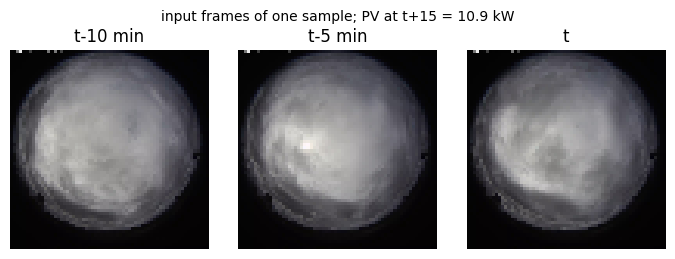

In [8]:
if not IMAGE_CACHE.exists():
    cache = np.lib.format.open_memmap(IMAGE_CACHE, mode="w+", dtype=np.uint8, shape=(len(minutes), 3, 64, 64))
    with h5py.File(H5_PATH, "r") as f:
        for split in ["trainval", "test"]:
            rows = np.flatnonzero(minutes["split"].to_numpy() == split)
            images = f[split]["images_log"][:]                      # whole split in memory
            for i in range(0, len(rows), 20_000):
                r = rows[i:i + 20_000]
                batch = images[minutes["img_idx"].to_numpy()[r]]     # (n, 64, 64, 3), BGR
                cache[r] = batch[..., ::-1].transpose(0, 3, 1, 2)    # RGB, channels first
            del images
    cache.flush()
    del cache

IMAGES = torch.from_numpy(np.load(IMAGE_CACHE)).to(DEVICE)
print("image cache:", tuple(IMAGES.shape), f"{IMAGES.numel() / 1e9:.1f} GB on {DEVICE}")

# check one image against the hdf5 file
with h5py.File(H5_PATH, "r") as f:
    row = 12345
    original = f[minutes.loc[row, "split"]]["images_log"][minutes.loc[row, "img_idx"]][..., ::-1]
assert (IMAGES[row].permute(1, 2, 0).cpu().numpy() == original).all()

# the three input frames of one sample
data = DATA[15]
i = np.flatnonzero(data.weather == "variable")[1000]
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
for ax, row, offset in zip(axes, data.image_rows[i], IMAGE_OFFSETS):
    ax.imshow(IMAGES[row].permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"t-{offset} min" if offset else "t")
    ax.axis("off")
plt.suptitle(f"input frames of one sample; PV at t+15 = {data.pv_target[i]:.1f} kW", fontsize=10)
plt.tight_layout()
plt.show()

### 7.2 CNN model

The three frames are stacked along the channel axis (9 channels), so the first layer can compare them and see how the clouds move. This follows SUNSET (Stanford), which stacks past frames in the same way. The network is trained from scratch:

| Part | Layers | Output |
|---|---|---|
| stem | 3×3 conv, 32 filters, BatchNorm, ReLU | 32 × 64 × 64 |
| block 1 | residual block (two 3×3 convs), max-pool, spatial dropout 0.1 | 32 × 32 × 32 |
| block 2 | residual block, max-pool, spatial dropout 0.1 | 64 × 16 × 16 |
| block 3 | residual block, max-pool, spatial dropout 0.1 | 128 × 8 × 8 |
| summary | average-pool to 4 × 4, flatten, linear 128, dropout 0.3 | 128 |

The 8 × 8 feature map of block 3 keeps **where** things are in the image (for example a cloud next to the sun). Pooling only to 4 × 4 keeps part of this location information. In the fusion model, the same encoder will provide these 64 positions as tokens for cross-attention. The image summary is joined with the sun position and passed to the same Student-t head; the target is k at t+h, converted back to kW as in section 6. Mixed precision (bfloat16) is used to speed up training.

**Against overfitting.** A first run without the two measures below reached its best early-stopping score after only 1–6 epochs in every fold and then got steadily worse on unseen days: the CNN overfits quickly, most likely because the several hundred images of one day are very similar, so the network can memorise individual days. Two standard measures are therefore used (the fusion models in `03_fusion` use the same image encoder):

1. **Data augmentation:** in every training batch the images are changed a little at random, the same way for the three frames of a sample, so the cloud movement between the frames is kept: brightness and contrast × 0.8–1.2, small noise (std 0.02), and a shift of up to 2 pixels. Rotations and flips are **not** used, because they would move the sun away from its true position, which the model also receives as an input. Early-stopping and evaluation images are never changed.
2. **Spatial dropout** (10%) after each block of the CNN: during training, 10% of the feature channels are switched off at random, so the network cannot rely on a few specific features to recognise a particular day.

In [9]:
class ResidualBlock(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.skip = nn.Identity() if c_in == c_out else nn.Sequential(nn.Conv2d(c_in, c_out, 1, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)) + self.skip(x))

class ImageEncoder(nn.Module):
    # 9-channel input (3 RGB frames) -> 128 x 8 x 8 feature map
    def __init__(self, in_channels=3 * len(IMAGE_OFFSETS), widths=(32, 64, 128), dropout=0.1):
        super().__init__()
        layers = [nn.Conv2d(in_channels, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU()]
        c = widths[0]
        for w in widths:
            layers += [ResidualBlock(c, w), nn.MaxPool2d(2), nn.Dropout2d(dropout)]   # spatial dropout
            c = w
        self.net = nn.Sequential(*layers)
        self.out_channels = c

    def forward(self, images):
        return self.net(images)

class ImageModel(nn.Module):
    use_amp = True

    def __init__(self, dropout=0.3):
        super().__init__()
        self.encoder = ImageEncoder()
        self.summary = nn.Sequential(nn.AdaptiveAvgPool2d(4), nn.Flatten(),
                                     nn.Linear(self.encoder.out_channels * 16, 128), nn.ReLU(), nn.Dropout(dropout))
        self.head = StudentTHead(128 + 6)

    def forward(self, batch):
        return self.head(torch.cat([self.summary(self.encoder(batch["images"])), batch["sun"]], dim=1))

def augment_frames(x):
    # x: (batch, 3 frames, 3, 64, 64) in [0, 1]; the same random change for the 3 frames of a sample,
    # so the movement of the clouds between the frames is kept
    b, dev = x.shape[0], x.device
    brightness = torch.empty(b, 1, 1, 1, 1, device=dev).uniform_(0.8, 1.2)
    contrast = torch.empty(b, 1, 1, 1, 1, device=dev).uniform_(0.8, 1.2)
    mean = x.mean(dim=(1, 2, 3, 4), keepdim=True)
    x = (x - mean) * contrast + mean * brightness + 0.02 * torch.randn_like(x)
    # shift of up to 2 pixels (no rotation or flip: they would move the sun away from its true position)
    theta = torch.zeros(b, 2, 3, device=dev)
    theta[:, 0, 0] = 1
    theta[:, 1, 1] = 1
    theta[:, :, 2] = torch.empty(b, 2, device=dev).uniform_(-2 / 32, 2 / 32)
    flat = x.flatten(1, 2)
    grid = F.affine_grid(theta, list(flat.shape), align_corners=False)
    flat = F.grid_sample(flat, grid, padding_mode="zeros", align_corners=False)
    return flat.view_as(x).clamp(0, 1)

def prepare_images(data, fit):
    target, to_kw = data.k_target, data.clear_sky_target
    s_mean, s_std = data.sun[fit].mean(0), data.sun[fit].std(0) + 1e-6
    y_mean, y_std = target[fit].mean(), target[fit].std()
    image_rows, sun = gpu(data.image_rows, torch.long), gpu((data.sun - s_mean) / s_std)

    def get_batch(idx, train=False):
        frames = IMAGES[image_rows[idx]].float().div_(255)             # (batch, 3 frames, 3, 64, 64) in [0, 1]
        if train:                                                      # augment training batches only
            frames = augment_frames(frames)
        return {"images": frames.flatten(1, 2),                        # (batch, 9, 64, 64)
                "sun": sun[idx]}
    return get_batch, gpu((target - y_mean) / y_std), (y_mean, y_std), to_kw

run_models({"sky_cnn": (ImageModel, prepare_images)})

sky_cnn, h=15:
  fold 0: 16 epochs (best 5), early-stop NLL 0.123, nu 4.22, 8.9 min
  fold 1: 21 epochs (best 10), early-stop NLL -0.013, nu 4.29, 12.1 min
  fold 2: 16 epochs (best 5), early-stop NLL 0.134, nu 4.20, 9.0 min
  fold 3: 20 epochs (best 9), early-stop NLL -0.208, nu 4.27, 11.5 min
  fold 4: 15 epochs (best 4), early-stop NLL -0.016, nu 4.17, 8.1 min
sky_cnn, h=30:
  fold 0: 17 epochs (best 6), early-stop NLL 0.207, nu 3.67, 8.3 min
  fold 1: 18 epochs (best 7), early-stop NLL 0.047, nu 3.72, 8.9 min
  fold 2: 17 epochs (best 6), early-stop NLL 0.168, nu 3.75, 8.3 min
  fold 3: 22 epochs (best 11), early-stop NLL -0.105, nu 3.78, 11.2 min
  fold 4: 16 epochs (best 5), early-stop NLL 0.086, nu 3.90, 8.4 min
sky_cnn, h=60:
  fold 0: 15 epochs (best 4), early-stop NLL 0.236, nu 3.18, 7.2 min
  fold 1: 19 epochs (best 8), early-stop NLL 0.080, nu 3.14, 10.3 min
  fold 2: 14 epochs (best 3), early-stop NLL 0.294, nu 3.32, 7.5 min
  fold 3: 21 epochs (best 10), early-stop NLL -0

## 8 · Results

All metrics are recomputed from the saved out-of-fold predictions, so this section can be run on its own after the models have been trained. Values are the mean ± std over the 5 folds; the skill score is computed against smart persistence on the same fold and weather bin.

In [10]:
MODEL_LABELS = {
    "persistence": "Persistence",
    "smart_persistence": "Smart persistence",
    "pv_mlp": "PV history – MLP",
    "pv_lstm": "PV history – LSTM",
    "pv_transformer": "PV history – Transformer",
    "k_mlp": "Clear-sky index history – MLP",
    "k_lstm": "Clear-sky index history – LSTM",
    "k_transformer": "Clear-sky index history – Transformer",
    "sky_cnn": "Sky images – CNN",
}
METRICS = ["RMSE", "MAE", "skill", "coverage", "width", "NLL", "CRPS", "Winkler"]

done = [m for m in MODEL_LABELS if all(prediction_file(m, h).exists() for h in HORIZONS)]
print("models with results:", ", ".join(done))

results = []
for model in done:
    for h in HORIZONS:
        r = evaluate_predictions(pd.read_csv(prediction_file(model, h)))
        r.insert(0, "model", model)
        r.insert(1, "horizon", h)
        results.append(r)
results = pd.concat(results, ignore_index=True)
reference = results[results["model"] == "smart_persistence"].set_index(["horizon", "fold", "weather"])["RMSE"]
results["skill"] = 1 - results["RMSE"] / reference.reindex(
    pd.MultiIndex.from_frame(results[["horizon", "fold", "weather"]])).to_numpy()
results.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)

def mean_std_table(h, weather="all", metrics=METRICS):
    r = results[(results["horizon"] == h) & (results["weather"] == weather)]
    g = r.groupby("model", sort=False)[metrics]
    table = g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)
    return table.rename(index=MODEL_LABELS)

for h in HORIZONS:
    print(f"\n=== {h}-minute horizon, all weather (mean ± std over 5 folds) ===")
    display(mean_std_table(h))

models with results: persistence, smart_persistence, pv_mlp, pv_lstm, pv_transformer, k_mlp, k_lstm, k_transformer, sky_cnn

=== 15-minute horizon, all weather (mean ± std over 5 folds) ===


,RMSE,MAE,skill,coverage,width,NLL,CRPS,Winkler
model,,,,,,,,
Persistence,2.568 ± 0.066,1.462 ± 0.043,-0.079 ± 0.005,0.940 ± 0.004,5.948 ± 0.191,1.883 ± 0.037,1.084 ± 0.034,10.058 ± 0.378
Smart persistence,2.379 ± 0.071,0.904 ± 0.055,0.000 ± 0.000,0.896 ± 0.009,3.329 ± 0.206,0.848 ± 0.087,0.740 ± 0.044,8.810 ± 0.502
PV history – MLP,2.102 ± 0.058,0.801 ± 0.055,0.116 ± 0.011,0.899 ± 0.006,3.368 ± 0.207,0.380 ± 0.112,0.603 ± 0.043,5.914 ± 0.452
PV history – LSTM,2.085 ± 0.054,0.798 ± 0.052,0.123 ± 0.014,0.901 ± 0.006,3.354 ± 0.280,0.390 ± 0.112,0.600 ± 0.042,5.860 ± 0.460
PV history – Transformer,2.105 ± 0.069,0.815 ± 0.056,0.115 ± 0.012,0.902 ± 0.013,3.523 ± 0.272,0.480 ± 0.080,0.612 ± 0.042,6.050 ± 0.456
Clear-sky index history – MLP,2.082 ± 0.056,0.791 ± 0.053,0.125 ± 0.008,0.901 ± 0.006,3.404 ± 0.206,0.366 ± 0.115,0.593 ± 0.042,5.788 ± 0.474
Clear-sky index history – LSTM,2.074 ± 0.058,0.785 ± 0.055,0.128 ± 0.015,0.900 ± 0.007,3.343 ± 0.205,0.360 ± 0.113,0.589 ± 0.043,5.782 ± 0.485
Clear-sky index history – Transformer,2.081 ± 0.058,0.797 ± 0.054,0.125 ± 0.010,0.896 ± 0.007,3.430 ± 0.284,0.384 ± 0.111,0.597 ± 0.042,5.895 ± 0.480
Sky images – CNN,2.115 ± 0.107,1.008 ± 0.072,0.111 ± 0.028,0.829 ± 0.037,3.404 ± 0.429,1.189 ± 0.073,0.737 ± 0.051,6.271 ± 0.379



=== 30-minute horizon, all weather (mean ± std over 5 folds) ===


,RMSE,MAE,skill,coverage,width,NLL,CRPS,Winkler
model,,,,,,,,
Persistence,3.308 ± 0.081,2.317 ± 0.048,-0.230 ± 0.015,0.944 ± 0.005,9.505 ± 0.209,2.419 ± 0.023,1.650 ± 0.038,13.175 ± 0.403
Smart persistence,2.690 ± 0.099,1.151 ± 0.064,0.000 ± 0.000,0.904 ± 0.009,4.608 ± 0.273,1.243 ± 0.071,0.913 ± 0.051,10.044 ± 0.637
PV history – MLP,2.373 ± 0.082,0.975 ± 0.065,0.118 ± 0.007,0.901 ± 0.013,4.198 ± 0.349,0.709 ± 0.108,0.738 ± 0.052,7.442 ± 0.633
PV history – LSTM,2.356 ± 0.082,0.973 ± 0.067,0.124 ± 0.012,0.899 ± 0.010,4.212 ± 0.413,0.720 ± 0.113,0.736 ± 0.054,7.398 ± 0.644
PV history – Transformer,2.364 ± 0.086,0.982 ± 0.069,0.121 ± 0.009,0.905 ± 0.011,4.289 ± 0.576,0.783 ± 0.117,0.743 ± 0.053,7.507 ± 0.632
Clear-sky index history – MLP,2.330 ± 0.097,0.958 ± 0.067,0.134 ± 0.013,0.904 ± 0.012,4.309 ± 0.313,0.689 ± 0.112,0.720 ± 0.052,7.152 ± 0.544
Clear-sky index history – LSTM,2.346 ± 0.070,0.959 ± 0.067,0.128 ± 0.019,0.893 ± 0.007,4.066 ± 0.319,0.686 ± 0.109,0.723 ± 0.052,7.215 ± 0.599
Clear-sky index history – Transformer,2.357 ± 0.077,0.966 ± 0.069,0.124 ± 0.015,0.890 ± 0.011,4.118 ± 0.293,0.696 ± 0.107,0.728 ± 0.053,7.310 ± 0.558
Sky images – CNN,2.349 ± 0.130,1.121 ± 0.072,0.127 ± 0.027,0.827 ± 0.028,3.661 ± 0.136,1.278 ± 0.069,0.824 ± 0.057,7.215 ± 0.657



=== 60-minute horizon, all weather (mean ± std over 5 folds) ===


,RMSE,MAE,skill,coverage,width,NLL,CRPS,Winkler
model,,,,,,,,
Persistence,4.896 ± 0.077,3.919 ± 0.060,-0.558 ± 0.034,0.940 ± 0.004,15.579 ± 0.244,2.948 ± 0.017,2.703 ± 0.042,18.418 ± 0.332
Smart persistence,3.146 ± 0.119,1.538 ± 0.080,0.000 ± 0.000,0.914 ± 0.010,6.629 ± 0.373,1.665 ± 0.063,1.178 ± 0.063,11.588 ± 0.757
PV history – MLP,2.658 ± 0.130,1.164 ± 0.086,0.155 ± 0.017,0.895 ± 0.004,5.016 ± 0.431,1.023 ± 0.105,0.886 ± 0.065,9.144 ± 0.666
PV history – LSTM,2.685 ± 0.158,1.182 ± 0.096,0.147 ± 0.028,0.892 ± 0.014,4.948 ± 0.401,1.057 ± 0.111,0.902 ± 0.075,9.330 ± 0.814
PV history – Transformer,2.672 ± 0.139,1.181 ± 0.085,0.151 ± 0.019,0.886 ± 0.013,4.809 ± 0.265,1.057 ± 0.108,0.898 ± 0.067,9.275 ± 0.767
Clear-sky index history – MLP,2.648 ± 0.131,1.159 ± 0.088,0.158 ± 0.018,0.894 ± 0.013,4.999 ± 0.311,1.015 ± 0.107,0.878 ± 0.068,8.930 ± 0.793
Clear-sky index history – LSTM,2.643 ± 0.148,1.157 ± 0.101,0.160 ± 0.032,0.892 ± 0.012,4.887 ± 0.368,1.020 ± 0.109,0.880 ± 0.072,8.985 ± 0.654
Clear-sky index history – Transformer,2.665 ± 0.151,1.164 ± 0.093,0.153 ± 0.025,0.901 ± 0.012,5.183 ± 0.344,1.021 ± 0.110,0.884 ± 0.066,9.119 ± 0.691
Sky images – CNN,2.628 ± 0.091,1.258 ± 0.066,0.165 ± 0.013,0.847 ± 0.053,4.508 ± 0.695,1.379 ± 0.058,0.930 ± 0.045,8.404 ± 0.506


In [11]:
# by weather bin (fold means)
fold_means = results.groupby(["model", "horizon", "weather"], sort=False)[METRICS].mean()
for metric in ["RMSE", "CRPS", "coverage", "width"]:
    table = fold_means[metric].unstack(["horizon", "weather"]).reindex(columns=["all"] + WEATHER_BINS, level=1)
    print(f"\n=== {metric} by horizon and weather ===")
    display(table.rename(index=MODEL_LABELS).round(3))


=== RMSE by horizon and weather ===


horizon                                   15                              30  \
weather                                  all  clear variable overcast    all   
model                                                                          
Persistence                            2.568  1.244    4.352    3.718  3.308   
Smart persistence                      2.379  0.741    4.247    3.657  2.690   
PV history – MLP                       2.102  0.716    3.662    3.432  2.373   
PV history – LSTM                      2.085  0.720    3.632    3.393  2.356   
PV history – Transformer               2.105  0.724    3.647    3.498  2.364   
Clear-sky index history – MLP          2.082  0.717    3.626    3.389  2.330   
Clear-sky index history – LSTM         2.074  0.717    3.619    3.343  2.346   
Clear-sky index history – Transformer  2.081  0.719    3.607    3.448  2.357   
Sky images – CNN                       2.115  0.819    3.465    3.947  2.349   

horizon                                                            60         \
weather                                clear variable overcast    all  clear   
model                                                                          
Persistence                            2.200    5.002    4.742  4.896  3.958   
Smart persistence                      0.996    4.590    4.564  3.146  1.267   
PV history – MLP                       0.943    3.951    4.206  2.658  1.158   
PV history – LSTM                      0.952    3.900    4.205  2.685  1.160   
PV history – Transformer               0.952    3.912    4.228  2.672  1.161   
Clear-sky index history – MLP          0.945    3.859    4.141  2.648  1.162   
Clear-sky index history – LSTM         0.948    3.888    4.169  2.643  1.159   
Clear-sky index history – Transformer  0.949    3.906    4.200  2.665  1.164   
Sky images – CNN                       1.006    3.746    4.468  2.628  1.197   

horizon                                                  
weather                               variable overcast  
model                                                    
Persistence                              6.509    6.427  
Smart persistence                        5.114    5.828  
PV history – MLP                         4.197    5.087  
PV history – LSTM                        4.237    5.167  
PV history – Transformer                 4.209    5.153  
Clear-sky index history – MLP            4.169    5.083  
Clear-sky index history – LSTM           4.167    5.062  
Clear-sky index history – Transformer    4.180    5.178  
Sky images – CNN                         3.995    5.319


=== CRPS by horizon and weather ===


horizon                                   15                              30  \
weather                                  all  clear variable overcast    all   
model                                                                          
Persistence                            1.084  0.649    2.163    1.654  1.650   
Smart persistence                      0.740  0.196    2.047    1.584  0.913   
PV history – MLP                       0.603  0.156    1.644    1.407  0.738   
PV history – LSTM                      0.600  0.157    1.625    1.406  0.736   
PV history – Transformer               0.612  0.163    1.643    1.451  0.743   
Clear-sky index history – MLP          0.593  0.156    1.614    1.368  0.720   
Clear-sky index history – LSTM         0.589  0.156    1.601    1.360  0.723   
Clear-sky index history – Transformer  0.597  0.157    1.609    1.422  0.728   
Sky images – CNN                       0.737  0.318    1.557    1.982  0.824   

horizon                                                            60         \
weather                                clear variable overcast    all  clear   
model                                                                          
Persistence                            1.226    2.661    2.338  2.703  2.277   
Smart persistence                      0.298    2.299    2.165  1.178  0.452   
PV history – MLP                       0.218    1.861    1.948  0.886  0.298   
PV history – LSTM                      0.221    1.840    1.959  0.902  0.302   
PV history – Transformer               0.228    1.847    1.965  0.898  0.304   
Clear-sky index history – MLP          0.218    1.807    1.877  0.878  0.298   
Clear-sky index history – LSTM         0.219    1.810    1.905  0.880  0.298   
Clear-sky index history – Transformer  0.219    1.821    1.929  0.884  0.301   
Sky images – CNN                       0.356    1.712    2.300  0.930  0.409   

horizon                                                  
weather                               variable overcast  
model                                                    
Persistence                              3.681    3.492  
Smart persistence                        2.676    3.039  
PV history – MLP                         2.023    2.638  
PV history – LSTM                        2.049    2.732  
PV history – Transformer                 2.029    2.730  
Clear-sky index history – MLP            1.995    2.613  
Clear-sky index history – LSTM           1.999    2.622  
Clear-sky index history – Transformer    2.001    2.657  
Sky images – CNN                         1.842    2.811


=== coverage by horizon and weather ===


horizon                                   15                              30  \
weather                                  all  clear variable overcast    all   
model                                                                          
Persistence                            0.940  0.972    0.869    0.860  0.944   
Smart persistence                      0.896  0.925    0.831    0.839  0.904   
PV history – MLP                       0.899  0.907    0.882    0.871  0.901   
PV history – LSTM                      0.901  0.913    0.881    0.853  0.899   
PV history – Transformer               0.902  0.912    0.883    0.872  0.905   
Clear-sky index history – MLP          0.901  0.907    0.888    0.882  0.904   
Clear-sky index history – LSTM         0.900  0.908    0.887    0.878  0.893   
Clear-sky index history – Transformer  0.896  0.899    0.898    0.861  0.890   
Sky images – CNN                       0.829  0.831    0.836    0.787  0.827   

horizon                                                            60         \
weather                                clear variable overcast    all  clear   
model                                                                          
Persistence                            0.972    0.888    0.872  0.940  0.957   
Smart persistence                      0.929    0.850    0.846  0.914  0.932   
PV history – MLP                       0.912    0.881    0.874  0.895  0.901   
PV history – LSTM                      0.908    0.884    0.866  0.892  0.904   
PV history – Transformer               0.916    0.884    0.873  0.886  0.899   
Clear-sky index history – MLP          0.907    0.893    0.909  0.894  0.899   
Clear-sky index history – LSTM         0.900    0.878    0.872  0.892  0.903   
Clear-sky index history – Transformer  0.893    0.885    0.875  0.901  0.907   
Sky images – CNN                       0.827    0.836    0.793  0.847  0.849   

horizon                                                  
weather                               variable overcast  
model                                                    
Persistence                              0.915    0.869  
Smart persistence                        0.878    0.859  
PV history – MLP                         0.876    0.899  
PV history – LSTM                        0.864    0.872  
PV history – Transformer                 0.858    0.858  
Clear-sky index history – MLP            0.878    0.902  
Clear-sky index history – LSTM           0.864    0.883  
Clear-sky index history – Transformer    0.889    0.884  
Sky images – CNN                         0.848    0.833


=== width by horizon and weather ===


horizon                                   15                              30  \
weather                                  all  clear variable overcast    all   
model                                                                          
Persistence                            5.948  3.736   11.838    7.423  9.505   
Smart persistence                      3.329  0.894    9.398    6.299  4.608   
PV history – MLP                       3.368  0.688    9.762    7.662  4.198   
PV history – LSTM                      3.354  0.705    9.747    7.308  4.212   
PV history – Transformer               3.523  0.709   10.391    7.438  4.289   
Clear-sky index history – MLP          3.404  0.697    9.951    7.454  4.309   
Clear-sky index history – LSTM         3.343  0.699    9.709    7.394  4.066   
Clear-sky index history – Transformer  3.430  0.660   10.259    7.098  4.118   
Sky images – CNN                       3.404  1.489    7.403    8.228  3.661   

horizon                                                             60  \
weather                                clear variable overcast     all   
model                                                                    
Persistence                            7.091   15.440   12.683  15.579   
Smart persistence                      1.426   12.037   10.110   6.629   
PV history – MLP                       0.948   11.371   11.251   5.016   
PV history – LSTM                      0.916   11.616   10.905   4.948   
PV history – Transformer               0.975   11.681   11.022   4.809   
Clear-sky index history – MLP          0.932   11.720   11.869   4.999   
Clear-sky index history – LSTM         0.915   11.097   10.626   4.887   
Clear-sky index history – Transformer  0.866   11.362   10.940   5.183   
Sky images – CNN                       1.546    7.979    9.404   4.508   

horizon                                                          
weather                                 clear variable overcast  
model                                                            
Persistence                            13.007   21.387   20.397  
Smart persistence                       2.301   15.617   17.356  
PV history – MLP                        1.198   12.183   16.953  
PV history – LSTM                       1.234   11.986   16.520  
PV history – Transformer                1.220   11.689   15.708  
Clear-sky index history – MLP           1.228   12.095   16.821  
Clear-sky index history – LSTM          1.250   11.692   16.401  
Clear-sky index history – Transformer   1.276   12.739   16.789  
Sky images – CNN                        1.909    9.355   12.739

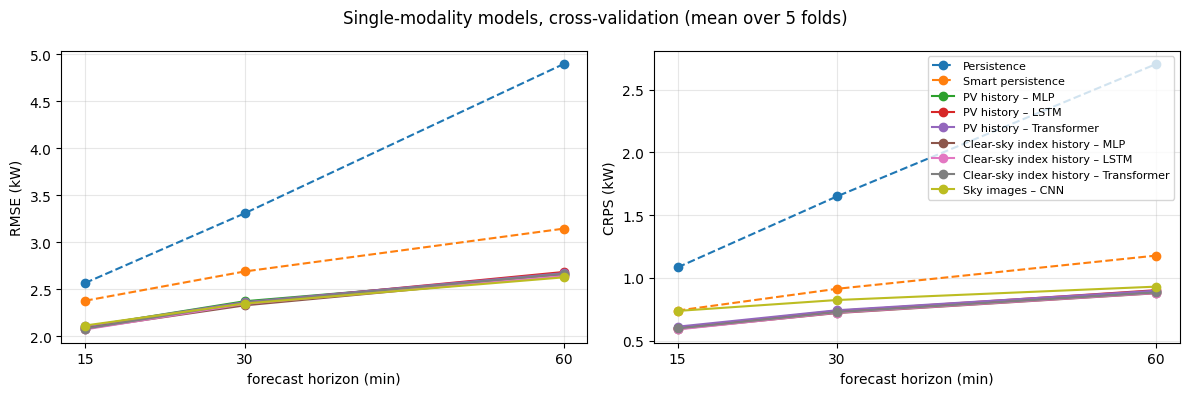

In [12]:
# RMSE and CRPS against horizon
all_weather = results[results["weather"] == "all"].groupby(["model", "horizon"], sort=False)[["RMSE", "CRPS"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["RMSE", "CRPS"]):
    for model in done:
        ax.plot(HORIZONS, all_weather.loc[model, metric], marker="o", label=MODEL_LABELS[model],
                linestyle="--" if "persistence" in model else "-")
    ax.set_xlabel("forecast horizon (min)")
    ax.set_ylabel(f"{metric} (kW)")
    ax.set_xticks(HORIZONS)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.suptitle("Single-modality models, cross-validation (mean over 5 folds)")
plt.tight_layout()
plt.show()